# 📊 Analyse des séries temporelles

> ✍️ **Notebook dirigé** · complétez les cellules marquées ✍️ À VOUS.

**Jour 1 · 11h20** · Exercice

*Analyse exploratoire et interprétation métier*

**Objectifs**
- Suivre la tendance du chiffre d'affaires avec des moyennes mobiles
- Mesurer la saisonnalité par décomposition
- Détecter une rupture et l'expliquer par les données

In [1]:
# ⚙️ À exécuter en premier : récupère la configuration du cours (quelques secondes)
import os, sys
CONFIG_ID = "1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r"

# Suppression du fichier corrompu s'il existe
if os.path.exists("config_projet.py"):
    os.remove("config_projet.py")

# Téléchargement propre avec gdown pour contourner l'avertissement de virus Google Drive
!gdown --id {CONFIG_ID} -O config_projet.py

print("✅ Configuration prête : chaque fichier de données se télécharge au premier usage")

✅ Configuration prête : chaque fichier de données se télécharge au premier usage


In [2]:
# Secteur traité : Crédit Azur (banque) — autres choix : "commerce", "hotellerie"
SECTEUR = "banque"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from config_projet import charger, reference, nettoyage_minimal

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
brut, cfg = charger(SECTEUR)
print(cfg["nom"], "·", brut.shape[0], "lignes,", brut.shape[1], "colonnes")

Crédit Azur · 20477 lignes, 20 colonnes


## 1. Le chiffre d'affaires mensuel
Agrégez par mois (`resample("MS")`) et tracez la courbe.

36 mois · 2023-01-01 → 2025-12-01
count        36.0
mean     295793.0
std       60587.0
min      184403.0
25%      260849.0
50%      295921.0
75%      317138.0
max      445205.0


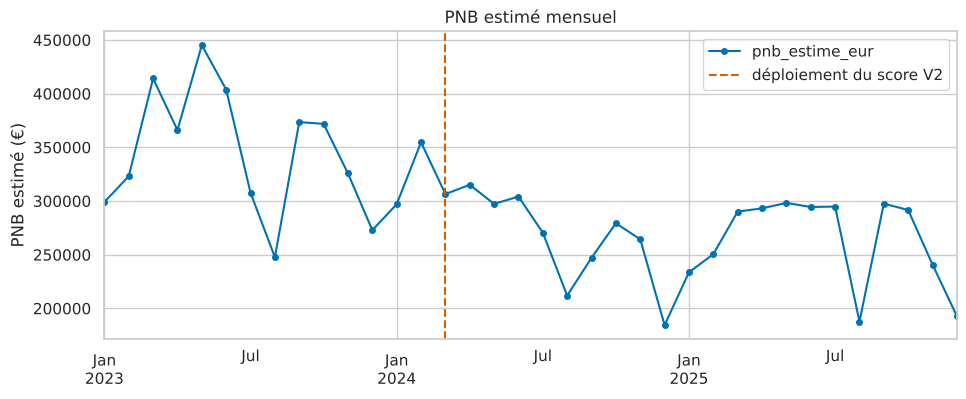

In [3]:
from config_projet import PALETTE
df = nettoyage_minimal(brut, cfg)
mensuel = df.set_index(cfg["date"])[cfg["ca"]].resample("MS").sum()
print(len(mensuel), "mois ·", mensuel.index.min().date(), "→", mensuel.index.max().date())
print(mensuel.describe().round(0).to_string())

ax = mensuel.plot(figsize=(11, 4), marker="o", ms=4, color=PALETTE[0])
ax.axvline(pd.Timestamp(cfg["evenement"][0]), color=PALETTE[5], ls="--", label=cfg["evenement"][1])
ax.set_title("PNB estimé mensuel"); ax.set_ylabel(cfg["ca_label"]); ax.set_xlabel(""); ax.legend()
plt.show()

## 2. Les moyennes mobiles
Ajoutez une moyenne mobile sur 3 mois et une sur 12 mois. Que montre chacune ?

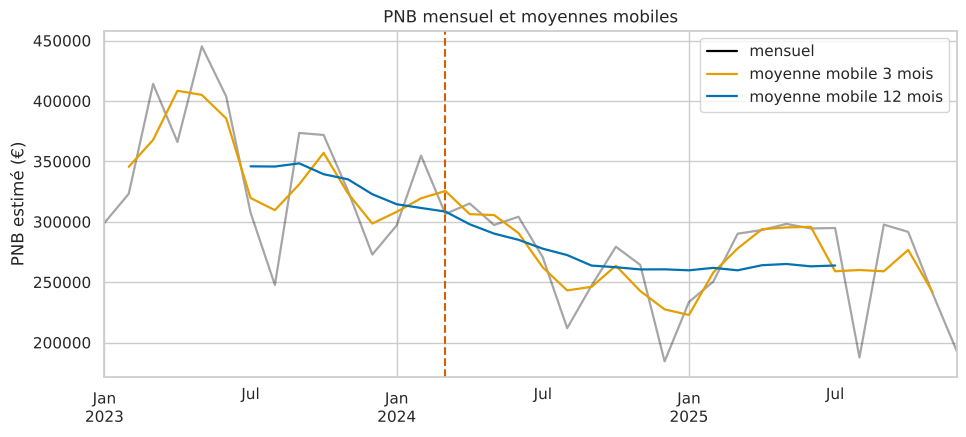

Tendance (MM 12 mois) : 345,893 € (07/2023) → 263,783 € (07/2025) soit -23.7%


In [4]:
lisse = pd.DataFrame({"mensuel": mensuel,
                      "moyenne mobile 3 mois": mensuel.rolling(3, center=True).mean(),
                      "moyenne mobile 12 mois": mensuel.rolling(12, center=True).mean()})
ax = lisse.plot(figsize=(11, 4.5), color=[PALETTE[7], PALETTE[1], PALETTE[0]], style=["-", "-", "-"], lw=1.6)
ax.lines[0].set_alpha(.35)
ax.axvline(pd.Timestamp(cfg["evenement"][0]), color=PALETTE[5], ls="--")
ax.set_title("PNB mensuel et moyennes mobiles"); ax.set_ylabel(cfg["ca_label"]); ax.set_xlabel("")
plt.show()
mm12 = lisse["moyenne mobile 12 mois"].dropna()
print(f"Tendance (MM 12 mois) : {mm12.iloc[0]:,.0f} € ({mm12.index[0]:%m/%Y}) → {mm12.iloc[-1]:,.0f} € ({mm12.index[-1]:%m/%Y}) "
      f"soit {mm12.iloc[-1] / mm12.iloc[0] - 1:+.1%}")

## 3. La décomposition saisonnière
Un événement exceptionnel fausse les coefficients saisonniers : remplacez d'abord les mois atypiques listés dans `cfg["atypiques"]` (les Jeux olympiques pour Les Escales) par la moyenne du même mois les autres années. Puis décomposez (`period=12`). Modèle additif ou multiplicatif : lequel convient, et pourquoi ?

Mois atypiques traités : aucun
résidu relatif · additif 0.053 · multiplicatif 0.053


,niveau,amplitude,amplitude / niveau
date_demande,,,
2023,345893.48,197522.50,0.57
2024,277703.27,170359.00,0.61
2025,263783.33,110528.25,0.42


Modèle retenu : multiplicatif


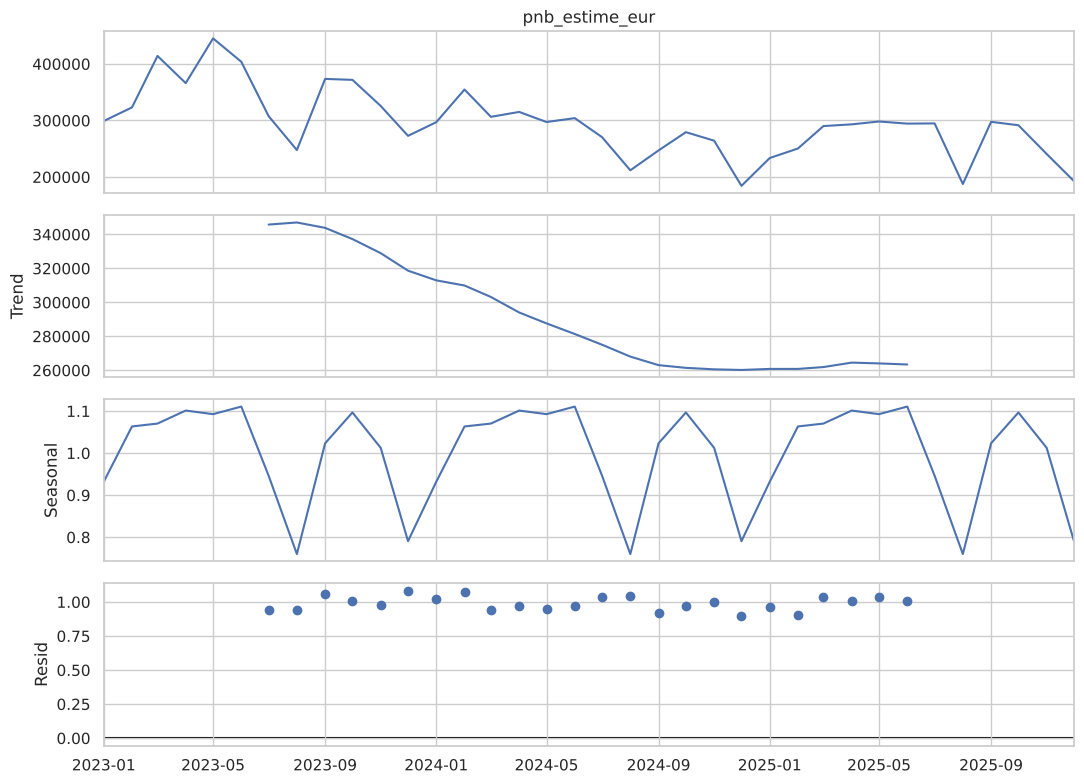

Coefficients saisonniers (1 = mois moyen) :
date_demande
Jun    1.111
Apr    1.101
Oct    1.097
May    1.093
Mar    1.070
Feb    1.063
Sep    1.023
Nov    1.013
Jul    0.946
Jan    0.932
Dec    0.791
Aug    0.760


In [5]:
from statsmodels.tsa.seasonal import seasonal_decompose
serie = mensuel.copy()
# Mois atypiques (aucun pour Crédit Azur) : remplacés par la moyenne du même mois les autres années
for mois in cfg["atypiques"]:
    mois = pd.Timestamp(mois)
    memes_mois = serie[(serie.index.month == mois.month) & (serie.index != mois)]
    serie.loc[mois] = memes_mois.mean()
print("Mois atypiques traités :", cfg["atypiques"] or "aucun")

# Additif ou multiplicatif ? On compare la dispersion relative du résidu et le lien niveau ↔ amplitude saisonnière
dec_add = seasonal_decompose(serie, model="additive", period=12)
dec_mul = seasonal_decompose(serie, model="multiplicative", period=12)
rel_add = (dec_add.resid / dec_add.trend).dropna().std()
rel_mul = (dec_mul.resid - 1).dropna().std()
print(f"résidu relatif · additif {rel_add:.3f} · multiplicatif {rel_mul:.3f}")
ampl = serie.groupby(serie.index.year).agg(niveau="mean", amplitude=lambda s: s.max() - s.min())
ampl["amplitude / niveau"] = ampl["amplitude"] / ampl["niveau"]
display(ampl.round(2))

# Résidus équivalents, mais l'amplitude saisonnière suit le niveau (elle fond avec le PNB) : modèle multiplicatif
dec = dec_mul
print("Modèle retenu : multiplicatif")
dec.plot().set_size_inches(11, 8); plt.tight_layout(); plt.show()

coef = dec.seasonal.iloc[:12].copy(); coef.index = coef.index.strftime("%b")
print("Coefficients saisonniers (1 = mois moyen) :"); print(coef.round(3).sort_values(ascending=False).to_string())

**Additif ou multiplicatif ?** **Multiplicatif.** Les deux modèles laissent le même résidu relatif (0,053), c'est donc l'amplitude saisonnière qui tranche : elle suit le niveau du PNB (écart entre le meilleur et le pire mois de 198 k€ en 2023, quand le niveau moyen est de 346 k€, contre 111 k€ en 2025 pour 264 k€ de moyenne), ce qui est la signature d'un effet proportionnel. Les coefficients se lisent en pourcentage d'un mois moyen : **juin 1,11, avril 1,10, octobre 1,10** (pics), **août 0,76 et décembre 0,79** (creux, −24 % et −21 %). Aucun mois atypique n'est à neutraliser pour Crédit Azur (`cfg["atypiques"]` est vide).

## 4. La croissance sur un an
Calculez la croissance par rapport au même mois de l'année précédente (`pct_change(12)`) et tracez-la avec la date de l'événement du brief (`cfg["evenement"]`).

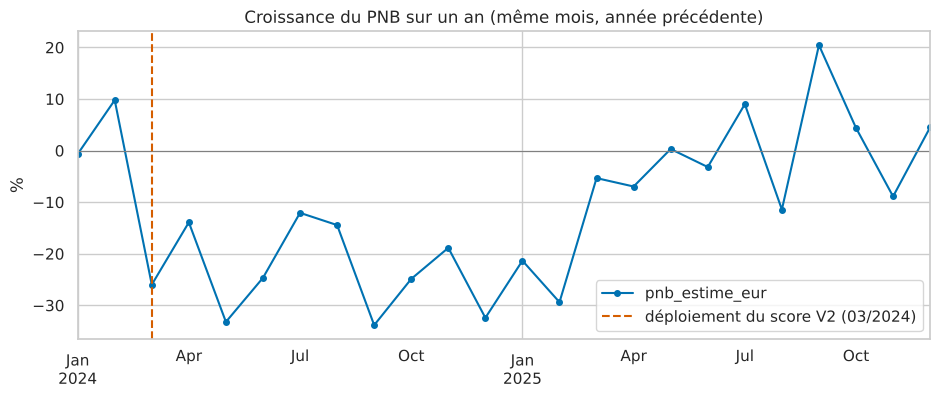

Moyenne avant l'événement : +4.6% · après : -12.8%
Dernier mois : 12/2025 +4.5%


In [6]:
yoy = mensuel.pct_change(12).dropna()
ax = (yoy * 100).plot(figsize=(11, 4), marker="o", ms=4, color=PALETTE[0])
ax.axhline(0, color="grey", lw=.8)
ev = pd.Timestamp(cfg["evenement"][0])
ax.axvline(ev, color=PALETTE[5], ls="--", label=f"{cfg['evenement'][1]} ({ev:%m/%Y})")
ax.set_title("Croissance du PNB sur un an (même mois, année précédente)"); ax.set_ylabel("%"); ax.set_xlabel(""); ax.legend()
plt.show()
print(f"Moyenne avant l'événement : {yoy[yoy.index < ev].mean():+.1%} · après : {yoy[yoy.index >= ev].mean():+.1%}")
print("Dernier mois :", f"{yoy.index[-1]:%m/%Y}", f"{yoy.iloc[-1]:+.1%}")

## 5. Localiser la rupture sans connaître la date
Retirez la saisonnalité (série ÷ coefficient saisonnier), puis cherchez le mois où l'écart entre la moyenne des 6 mois suivants et celle des 6 mois précédents est le plus fort. Vérifiez avec un test de Student.

Rupture détectée : 03/2024 · moyenne 6 mois avant 337,195 € → après 280,524 € (-16.8%)
Test de Student (Welch) : t = -7.65 · p = 1.84e-04
Événement du brief : 2024-03-01 → décalage : 0 jours


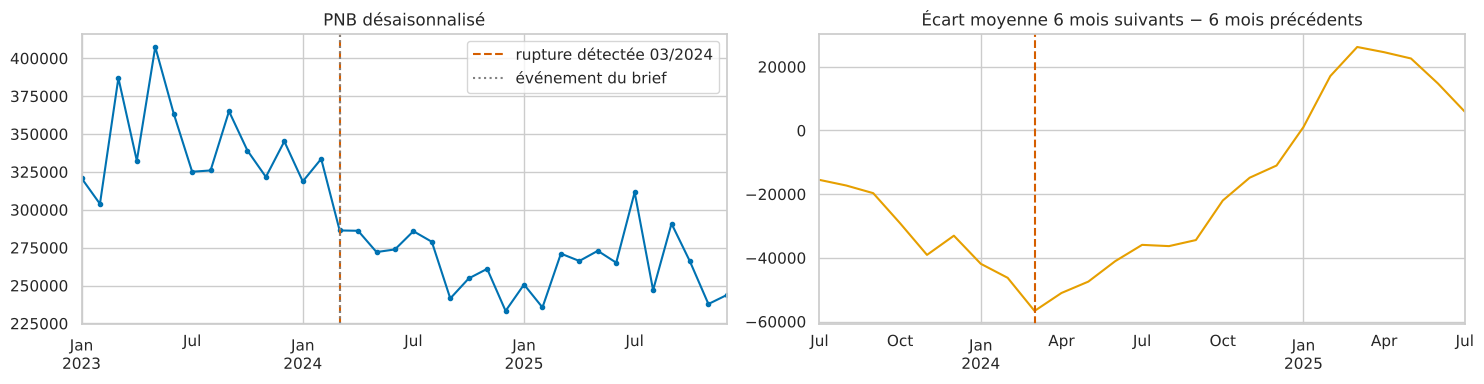

In [7]:
from scipy import stats
desaison = serie / dec.seasonal
ecarts = {}
for i in range(6, len(desaison) - 5):                      # 6 mois avant, 6 mois à partir de i
    ecarts[desaison.index[i]] = desaison.iloc[i:i + 6].mean() - desaison.iloc[i - 6:i].mean()
ecarts = pd.Series(ecarts)
rupture = ecarts.abs().idxmax()
i = desaison.index.get_loc(rupture)
avant, apres = desaison.iloc[i - 6:i], desaison.iloc[i:i + 6]
t, p = stats.ttest_ind(apres, avant, equal_var=False)
print(f"Rupture détectée : {rupture:%m/%Y} · moyenne 6 mois avant {avant.mean():,.0f} € → après {apres.mean():,.0f} € "
      f"({apres.mean() / avant.mean() - 1:+.1%})")
print(f"Test de Student (Welch) : t = {t:.2f} · p = {p:.2e}")
print("Événement du brief :", cfg["evenement"][0], "→ décalage :", (rupture - pd.Timestamp(cfg["evenement"][0])).days, "jours")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
desaison.plot(ax=axes[0], color=PALETTE[0], marker="o", ms=3)
axes[0].axvline(rupture, color=PALETTE[5], ls="--", label=f"rupture détectée {rupture:%m/%Y}")
axes[0].axvline(pd.Timestamp(cfg["evenement"][0]), color="grey", ls=":", label="événement du brief")
axes[0].set_title("PNB désaisonnalisé"); axes[0].legend(); axes[0].set_xlabel("")
ecarts.plot(ax=axes[1], color=PALETTE[1]); axes[1].axvline(rupture, color=PALETTE[5], ls="--")
axes[1].set_title("Écart moyenne 6 mois suivants − 6 mois précédents"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

**Votre lecture** : la méthode trouve la rupture en **mars 2024**, soit le mois du déploiement du score V2 (écart de 0 jour avec l'événement du brief). Une fois la saisonnalité retirée, le PNB mensuel passe de **337 k€ à 281 k€ (−16,8 %)**, test de Student (Welch) t = −7,65, p = 1,8·10⁻⁴. La croissance sur un an passe d'une moyenne de **+4,6 % avant** à **−12,8 % après** la bascule. Le retour à +4,5 % en décembre 2025 est trompeur : il compare à un décembre 2024 déjà bas, et la tendance sur 12 mois reste à 264 k€ contre 346 k€ mi-2023 (−24 %). C'est une **rupture durable**, pas un pic, et elle a un fait métier : le score V2.

## 6. Expliquer la rupture
Qu'est-ce qui change autour de la rupture ? Comparez la part de chaque segment dans le chiffre d'affaires, par trimestre.

date_demande,2023-01-01,2023-04-01,2023-07-01,2023-10-01,2024-01-01,2024-04-01,2024-07-01,2024-10-01,2025-01-01,2025-04-01,2025-07-01,2025-10-01
type_credit,,,,,,,,,,,,
auto,46.3,51.2,47.3,49.8,49.5,47.1,48.3,43.8,45.9,48.9,49.2,48.0
personnel,14.8,14.4,13.6,14.2,15.1,16.6,14.6,14.2,15.5,16.3,14.5,13.4
renouvelable,1.4,1.2,1.2,1.1,1.3,1.3,1.4,1.3,1.2,1.3,1.5,1.5
travaux,37.5,33.2,38.0,34.8,34.2,35.0,35.6,40.7,37.4,33.4,34.9,37.0


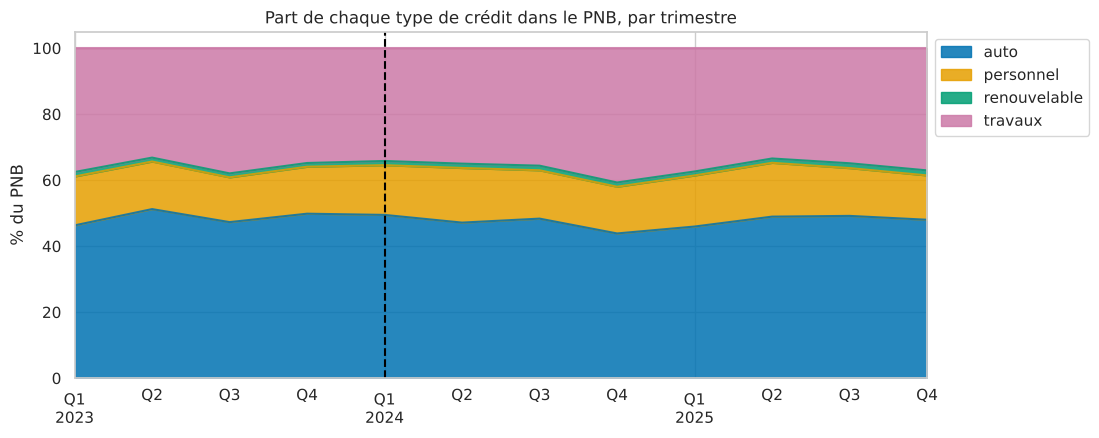

Taux d'accord par type de crédit :


p,avant,après
type_credit,,
auto,0.737,0.539
personnel,0.769,0.577
renouvelable,0.767,0.574
travaux,0.776,0.589


Demandes par mois et par type de crédit (volume) :


p,avant,après
type_credit,,
auto,163.0,172.0
personnel,164.0,174.0
renouvelable,77.0,89.0
travaux,138.0,146.0


In [8]:
seg = cfg["segment"]
trim = df.groupby([pd.Grouper(key=cfg["date"], freq="QS"), seg])[cfg["ca"]].sum().unstack()
parts = trim.div(trim.sum(axis=1), axis=0) * 100
display(parts.round(1).T)
ax = parts.plot.area(figsize=(11, 4.5), color=PALETTE[:parts.shape[1]], alpha=.85)
ax.axvline(pd.Timestamp(cfg["evenement"][0]), color="black", ls="--")
ax.set_title("Part de chaque type de crédit dans le PNB, par trimestre"); ax.set_ylabel("% du PNB"); ax.set_xlabel("")
ax.legend(bbox_to_anchor=(1, 1)); plt.show()

# Le volume et la décision, par segment, avant / après l'événement
ev = pd.Timestamp(cfg["evenement"][0])
periode = np.where(df[cfg["date"]] < ev, "avant", "après")
print("Taux d'accord par type de crédit :")
display(df.assign(p=periode).pivot_table(index=seg, columns="p", values=cfg["decision"], aggfunc="mean").round(3)[["avant", "après"]])
print("Demandes par mois et par type de crédit (volume) :")
nb_mois = {"avant": mensuel.index[mensuel.index < ev].size, "après": mensuel.index[mensuel.index >= ev].size}
vol = df.assign(p=periode).groupby([seg, "p"]).size().unstack()[["avant", "après"]]
display((vol / pd.Series(nb_mois)).round(0))

## 7. Bonus · un indicateur de la banque
Pour Crédit Azur, le chiffre d'affaires dépend du **taux d'accord**. Tracez le taux d'accord mensuel : la rupture y est-elle plus nette ?

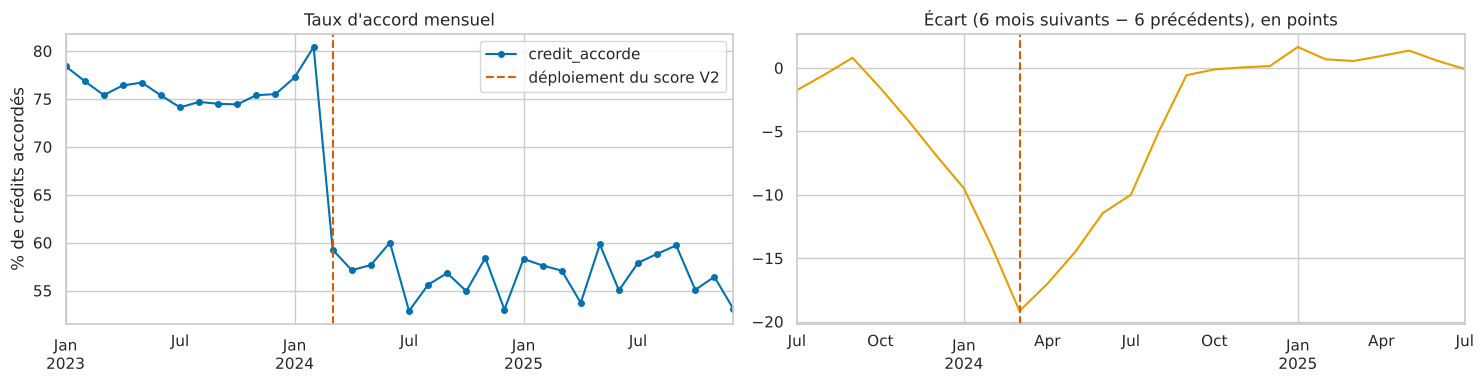

Rupture du taux d'accord : 03/2024 · 76.2% → 57.1% (-19.2 pts) · t = -13.6 · p = 1.1e-07


,demandes,taux,pnb_par_credit,pnb,mois,pnb_mensuel,demandes_par_mois
p,,,,,,,
avant,7585,0.76,832.32,4802491.75,13.96,343971.41,543.26
après,12799,0.57,804.14,5846069.25,22.01,265603.50,581.49


In [9]:
taux_mensuel = df.set_index(cfg["date"])[cfg["decision"]].resample("MS").mean()
ev = pd.Timestamp(cfg["evenement"][0])
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
(taux_mensuel * 100).plot(ax=axes[0], marker="o", ms=4, color=PALETTE[0])
axes[0].axvline(ev, color=PALETTE[5], ls="--", label=cfg["evenement"][1])
axes[0].set_title("Taux d'accord mensuel"); axes[0].set_ylabel("% de crédits accordés"); axes[0].set_xlabel(""); axes[0].legend()

# Même méthode de détection que pour le PNB (sans saisonnalité à retirer : le taux n'en a pas, on le vérifie)
ecarts_t = pd.Series({taux_mensuel.index[i]: taux_mensuel.iloc[i:i + 6].mean() - taux_mensuel.iloc[i - 6:i].mean()
                      for i in range(6, len(taux_mensuel) - 5)})
rupt = ecarts_t.abs().idxmax(); i = taux_mensuel.index.get_loc(rupt)
ecarts_t.mul(100).plot(ax=axes[1], color=PALETTE[1]); axes[1].axvline(rupt, color=PALETTE[5], ls="--")
axes[1].set_title("Écart (6 mois suivants − 6 précédents), en points"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()
a, b = taux_mensuel.iloc[i - 6:i], taux_mensuel.iloc[i:i + 6]
t, p = stats.ttest_ind(b, a, equal_var=False)
print(f"Rupture du taux d'accord : {rupt:%m/%Y} · {a.mean():.1%} → {b.mean():.1%} ({(b.mean() - a.mean()) * 100:+.1f} pts) · t = {t:.1f} · p = {p:.1e}")
# Part de la baisse du PNB expliquée par le taux d'accord : PNB ≈ demandes × taux d'accord × PNB par crédit accordé
m = df.assign(p=np.where(df[cfg["date"]] < ev, "avant", "après")).groupby("p").agg(
    demandes=("demande_id", "size"), taux=("credit_accorde", "mean"),
    pnb_par_credit=(cfg["ca"], lambda s: s[s > 0].mean()), pnb=(cfg["ca"], "sum"))
m["mois"] = [(pd.Timestamp("2025-12-31") - ev).days / 30.44, (ev - pd.Timestamp("2023-01-01")).days / 30.44]
m["pnb_mensuel"] = m["pnb"] / m["mois"]; m["demandes_par_mois"] = m["demandes"] / m["mois"]
display(m.loc[["avant", "après"]].round(2))

**Vos conclusions**
1. **Saisonnalité :** le PNB est saisonnier, avec un pic en juin (coefficient 1,11) et des creux en août (0,76) et décembre (0,79), soit 35 points d'écart entre juin et août.
2. **Rupture :** elle intervient en mars 2024, au déploiement du score V2 ; le PNB désaisonnalisé perd 17 % (337 k€ → 281 k€ par mois, p < 0,001).
3. **Explication :** la cause est le **taux d'accord**, qui chute de 76 % à 57 % (−19 points, rupture détectée aussi en mars 2024, p ≈ 10⁻⁷), alors que le volume de demandes augmente (543 → 581 par mois, +7 %) et que le PNB par crédit accordé reste stable (832 € → 804 €, −3 %). La baisse touche tous les types de crédit (−19 à −20 points) et la structure du PNB ne bouge pas (le crédit auto reste vers 48 %) : c'est une décision de score, pas un effet de produit.

💾 **Versionnez** : *Fichier › Enregistrer une copie dans GitHub*, message de commit : « Séries temporelles : saisonnalité et rupture »